In [1]:
!pip install tensorflow pandas numpy matplotlib scikit-learn scipy -q

In [2]:
import random
import pickle
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.preprocessing import MinMaxScaler

# ---------------- Configuração ----------------
SEED = 42
CSV_PATH = 'Steel_industry_data.csv'
SEQ_LENGTH = 60          # janela de 60 passos de 15 min (15 h)
TRAIN_RATIO = 0.80       # hold-out temporal 80/20
VAL_SPLIT = 0.20         # 20% do treino para validação interna
PATIENCE = 10            # Early Stopping
EPOCHS_LSTM = 150
EPOCHS_GRU = 50
CLIP_OUTLIERS = False    # True: limita (winsorize) os outliers do IQR; False: apenas reporta

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

FEATURES = ['Usage_kWh',
            'Lagging_Current_Reactive.Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh',
            'Lagging_Current_Power_Factor',
            'Leading_Current_Power_Factor']

# ---------------- Carga e limpeza ----------------
df = pd.read_csv(CSV_PATH)
print(f"Arquivo carregado. Shape: {df.shape}")

df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')
df = df.sort_values('date').reset_index(drop=True)

n_missing = int(df[FEATURES].isnull().sum().sum())
print(f"Valores ausentes nas features: {n_missing}")
if n_missing > 0:
    # lacunas curtas (até 2 h): interpolação linear; lacunas longas: interpolação cúbica
    df[FEATURES] = df[FEATURES].interpolate(method='linear', limit=8, limit_area='inside')
    if df[FEATURES].isnull().any().any():
        df[FEATURES] = df[FEATURES].interpolate(method='cubic', limit_area='inside')
    df[FEATURES] = df[FEATURES].bfill().ffill()

df = df.set_index('date')

N_TRAIN_ROWS = int(len(df) * TRAIN_RATIO)

# Outliers pelo IQR, com limites calculados somente nas linhas de treino
q1 = df[FEATURES].iloc[:N_TRAIN_ROWS].quantile(0.25)
q3 = df[FEATURES].iloc[:N_TRAIN_ROWS].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (df[FEATURES] < low) | (df[FEATURES] > high)
print("\nOutliers pelo IQR (por variável):")
print(outlier_mask.sum().to_string())
if CLIP_OUTLIERS:
    df[FEATURES] = df[FEATURES].clip(lower=low, upper=high, axis=1)
    print("\nOutliers limitados aos limites do IQR.")
else:
    print("\nOutliers mantidos (CLIP_OUTLIERS=False): picos altos de consumo são justamente os candidatos a gargalo.")

print(f"\nLinhas totais: {len(df)} | treino: {N_TRAIN_ROWS} | teste: {len(df) - N_TRAIN_ROWS}")


def create_sequences(arr, seq_length, with_target=True):
    X, y = [], []
    for i in range(len(arr) - seq_length + (0 if with_target else 1)):
        X.append(arr[i:i + seq_length])
        if with_target:
            y.append(arr[i + seq_length, 0])
    return (np.array(X), np.array(y)) if with_target else np.array(X)

Arquivo carregado. Shape: (35040, 11)
Valores ausentes nas features: 0

Outliers pelo IQR (por variável):
Usage_kWh                                322
Lagging_Current_Reactive.Power_kVarh    1062
Leading_Current_Reactive_Power_kVarh    7759
Lagging_Current_Power_Factor               1
Leading_Current_Power_Factor            8551

Outliers mantidos (CLIP_OUTLIERS=False): picos altos de consumo são justamente os candidatos a gargalo.

Linhas totais: 35040 | treino: 28032 | teste: 7008


## LSTM (previsão de consumo)

In [3]:
print("PREPARAÇÃO DOS DADOS PARA LSTM\n")

data = df[FEATURES].values

# Scaler ajustado somente no treino
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(data[:N_TRAIN_ROWS])
scaled = scaler.transform(data)

# Treino: janelas dentro do treino. Teste: o histórico (SEQ_LENGTH passos) vem do fim do treino,
# mas os alvos são todos do período de teste.
X_train, y_train = create_sequences(scaled[:N_TRAIN_ROWS], SEQ_LENGTH)
X_test, y_test = create_sequences(scaled[N_TRAIN_ROWS - SEQ_LENGTH:], SEQ_LENGTH)

print(f"Treino: X={X_train.shape}, y={y_train.shape}")
print(f"Teste:  X={X_test.shape}, y={y_test.shape}\n")

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LENGTH, len(FEATURES))),
    tf.keras.layers.LSTM(128, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1)

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS_LSTM,
    batch_size=64,
    validation_split=VAL_SPLIT,   # últimos 20% do treino (ordem temporal preservada)
    callbacks=[early_stop],
    verbose=1
)

model.save('lstm_model.keras')
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("\nSalvos: lstm_model.keras e scaler.pkl")

PREPARAÇÃO DOS DADOS PARA LSTM

Treino: X=(27972, 60, 5), y=(27972,)
Teste:  X=(7008, 60, 5), y=(7008,)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 128)        │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,465 (509.63 KB)

 Trainable params: 130,465 (509.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.0189 - mae: 0.0910 - val_loss: 0.0065 - val_mae: 0.0460
Epoch 2/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0099 - mae: 0.0624 - val_loss: 0.0061 - val_mae: 0.0455
Epoch 3/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0087 - mae: 0.0573 - val_loss: 0.0055 - val_mae: 0.0426
Epoch 4/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0084 - mae: 0.0558 - val_loss: 0.0050 - val_mae: 0.0400
Epoch 5/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0079 - mae: 0.0539 - val_loss: 0.0049 - val_mae: 0.0403
Epoch 6/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0074 - mae: 0.0518 - val_loss: 0.0048 - val_mae: 0.0398
Epoch 7/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.0072 - mae: 0.0506 - val_loss: 0.0045 - val_mae: 0.0383
Epoch 8/150
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.0070 - mae: 0.0493 - val_loss: 0.0043 - val_mae: 0.0373
Epoch 9/150
350/350 ━━━━━━━━━━━━━━━━━━━

AVALIAÇÃO DO LSTM NO CONJUNTO DE TESTE

MAE:  5.00 kWh
RMSE: 9.05 kWh
R²:   0.9169

DETECÇÃO DE GARGALOS (LSTM)

Critério: erro > MAE + 1.5σ = 16.31 kWh
Gargalos identificados: 534 de 7008 períodos (7.62%)
Erro médio nos gargalos: 26.41 kWh
Consumo médio real nos gargalos: 69.71 kWh

Top 10 períodos com maior erro
Índice   Real (kWh)   Previsto (kWh)   Erro (kWh)  
2756        23.11          94.13          71.02
1508         9.47          77.54          68.07
2676        23.00          89.63          66.63
5805       140.80          74.66          66.14
0            2.81          66.69          63.88
426        129.85          70.48          59.37
1042       113.98          54.78          59.20
1131       113.58          57.87          55.71
5817       149.18          94.22          54.96
2467       120.85          68.72          52.13


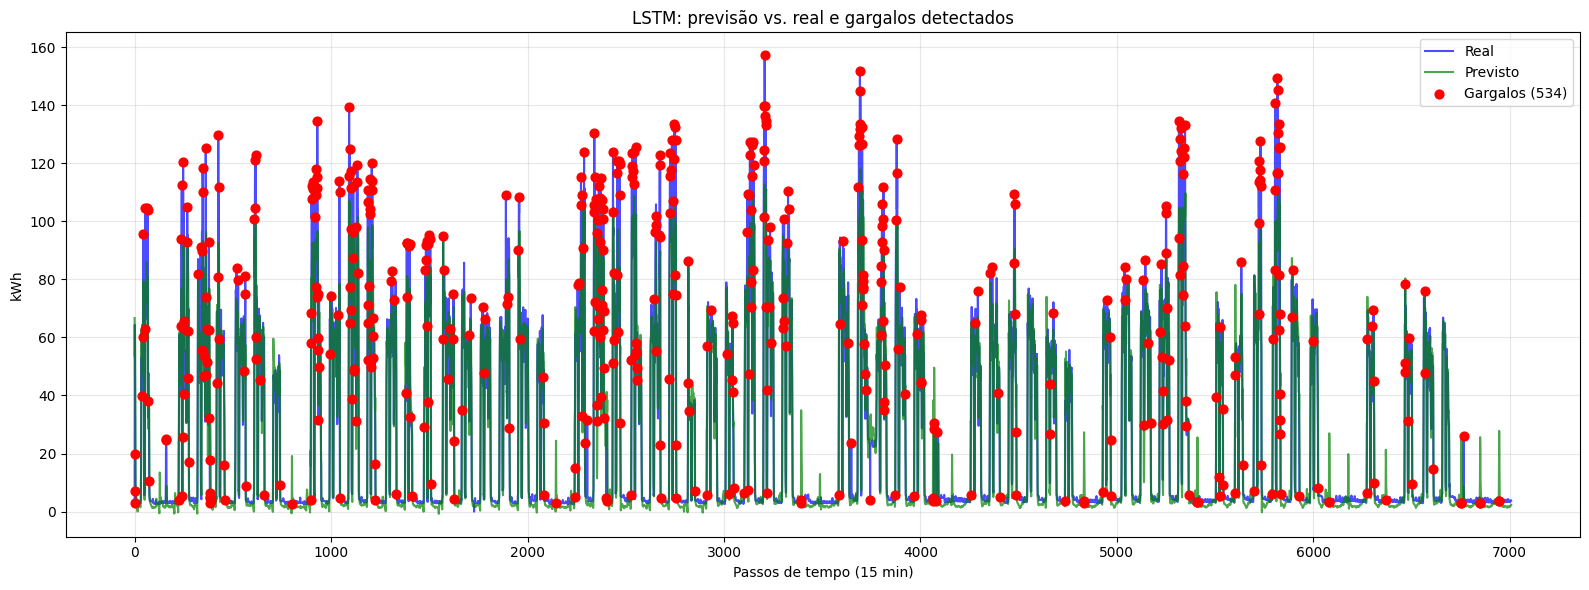

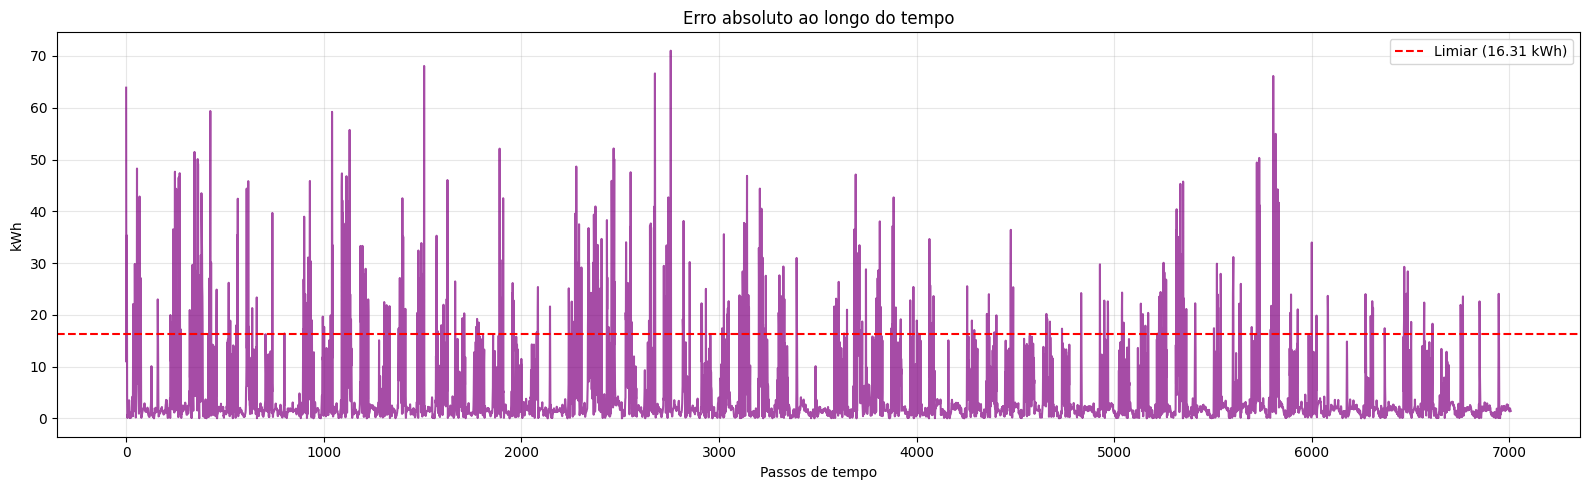

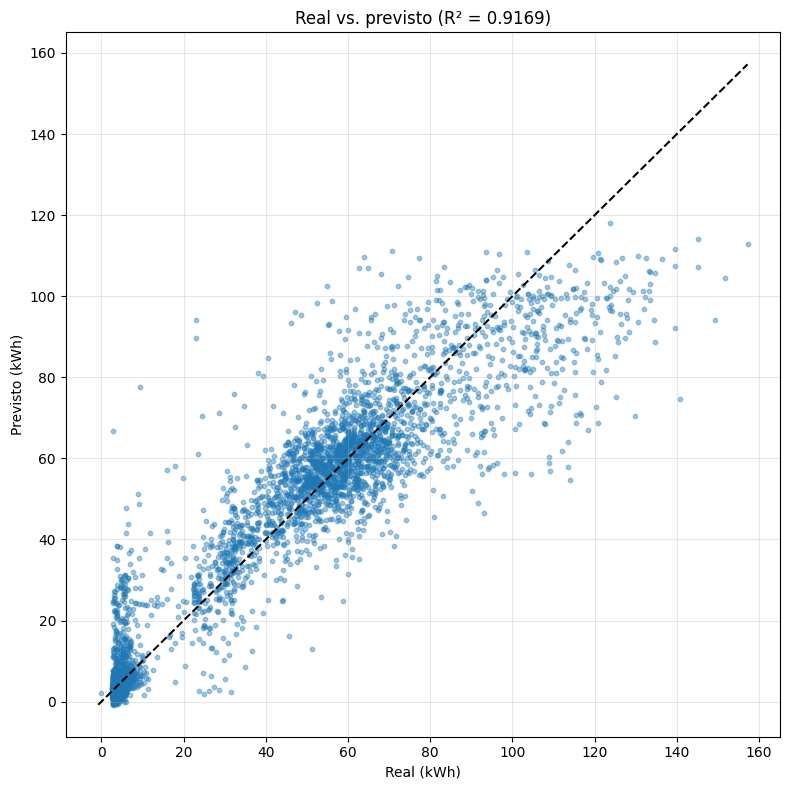

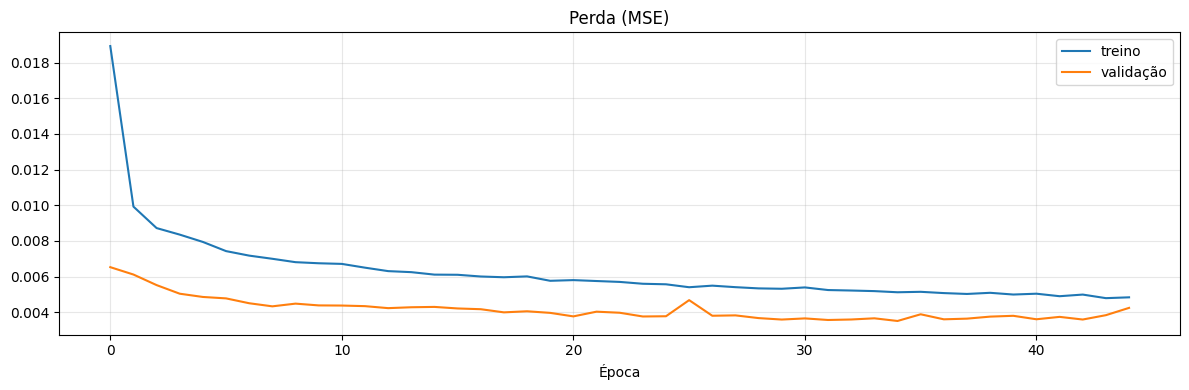

In [4]:
print("AVALIAÇÃO DO LSTM NO CONJUNTO DE TESTE\n")

pred_scaled = model.predict(X_test, verbose=0).flatten()

# Inversão da normalização apenas da coluna 0 (Usage_kWh)
rng, mn = scaler.data_range_[0], scaler.data_min_[0]
predictions_actual = pred_scaled * rng + mn
y_test_actual = y_test * rng + mn

mae_actual = mean_absolute_error(y_test_actual, predictions_actual)
rmse_actual = np.sqrt(mean_squared_error(y_test_actual, predictions_actual))
r2_actual = r2_score(y_test_actual, predictions_actual)

print(f"MAE:  {mae_actual:.2f} kWh")
print(f"RMSE: {rmse_actual:.2f} kWh")
print(f"R²:   {r2_actual:.4f}\n")

print("DETECÇÃO DE GARGALOS (LSTM)\n")
residuos = np.abs(y_test_actual - predictions_actual)
threshold_gargalo = mae_actual + 1.5 * np.std(residuos)
indices_gargalos = np.where(residuos > threshold_gargalo)[0]
percentual_gargalos = 100 * len(indices_gargalos) / len(residuos)

print(f"Critério: erro > MAE + 1.5σ = {threshold_gargalo:.2f} kWh")
print(f"Gargalos identificados: {len(indices_gargalos)} de {len(residuos)} períodos ({percentual_gargalos:.2f}%)")
if len(indices_gargalos) > 0:
    print(f"Erro médio nos gargalos: {np.mean(residuos[indices_gargalos]):.2f} kWh")
    print(f"Consumo médio real nos gargalos: {np.mean(y_test_actual[indices_gargalos]):.2f} kWh")

print("\nTop 10 períodos com maior erro")
print(f"{'Índice':<8} {'Real (kWh)':<12} {'Previsto (kWh)':<16} {'Erro (kWh)':<12}")
for idx in np.argsort(residuos)[-10:][::-1]:
    print(f"{idx:<8} {y_test_actual[idx]:>8.2f}     {predictions_actual[idx]:>10.2f}       {residuos[idx]:>8.2f}")

# ---------------- Gráficos ----------------
plt.figure(figsize=(16, 6))
plt.plot(y_test_actual, label='Real', color='blue', alpha=0.7)
plt.plot(predictions_actual, label='Previsto', color='green', alpha=0.7)
plt.scatter(indices_gargalos, y_test_actual[indices_gargalos], color='red', s=40,
            label=f'Gargalos ({len(indices_gargalos)})', zorder=5)
plt.title('LSTM: previsão vs. real e gargalos detectados')
plt.xlabel('Passos de tempo (15 min)'); plt.ylabel('kWh'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(16, 5))
plt.plot(residuos, color='purple', alpha=0.7)
plt.axhline(threshold_gargalo, color='red', linestyle='--', label=f'Limiar ({threshold_gargalo:.2f} kWh)')
plt.title('Erro absoluto ao longo do tempo'); plt.xlabel('Passos de tempo'); plt.ylabel('kWh')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 8))
plt.scatter(y_test_actual, predictions_actual, s=10, alpha=0.4)
lim = [min(y_test_actual.min(), predictions_actual.min()), max(y_test_actual.max(), predictions_actual.max())]
plt.plot(lim, lim, 'k--'); plt.title(f'Real vs. previsto (R² = {r2_actual:.4f})')
plt.xlabel('Real (kWh)'); plt.ylabel('Previsto (kWh)'); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 4))
plt.plot(history.history['loss'], label='treino'); plt.plot(history.history['val_loss'], label='validação')
plt.title('Perda (MSE)'); plt.xlabel('Época'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## GRU Autoencoder (detecção de anomalias)

In [5]:
print("PREPARAÇÃO DOS DADOS PARA GRU AUTOENCODER\n")

usage = df[['Usage_kWh']].values

scaler_gru = MinMaxScaler(feature_range=(0, 1))
scaler_gru.fit(usage[:N_TRAIN_ROWS])           # somente treino
usage_scaled = scaler_gru.transform(usage)

train_data = usage_scaled[:N_TRAIN_ROWS]
test_data = usage_scaled[N_TRAIN_ROWS:]

X_train_g = create_sequences(train_data, SEQ_LENGTH, with_target=False)
X_test_g = create_sequences(test_data, SEQ_LENGTH, with_target=False)
print(f"X_train: {X_train_g.shape} | X_test: {X_test_g.shape}\n")

gru = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LENGTH, 1)),
    tf.keras.layers.GRU(128),                                   # encoder
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.RepeatVector(SEQ_LENGTH),
    tf.keras.layers.GRU(128, return_sequences=True),            # decoder
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))
])
gru.compile(optimizer='adam', loss='mae')
gru.summary()

early_stop_g = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=PATIENCE, mode='min', restore_best_weights=True, verbose=1)

history_g = gru.fit(
    X_train_g, X_train_g,
    epochs=EPOCHS_GRU,
    batch_size=32,
    validation_split=VAL_SPLIT,
    callbacks=[early_stop_g],
    verbose=1
)

gru.save('gru_autoencoder_model.keras')
with open('scaler_gru.pkl', 'wb') as f:
    pickle.dump(scaler_gru, f)
print("\nSalvos: gru_autoencoder_model.keras e scaler_gru.pkl")

PREPARAÇÃO DOS DADOS PARA GRU AUTOENCODER

X_train: (27973, 60, 1) | X_test: (6949, 60, 1)



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 128)            │        50,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 60, 128)        │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 60, 1)          │           129 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 149,505 (584.00 KB)

 Trainable params: 149,505 (584.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 16s 17ms/step - loss: 0.1134 - val_loss: 0.0615
Epoch 2/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0724 - val_loss: 0.0519
Epoch 3/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0666 - val_loss: 0.0482
Epoch 4/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0621 - val_loss: 0.0469
Epoch 5/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0572 - val_loss: 0.0429
Epoch 6/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0539 - val_loss: 0.0403
Epoch 7/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0520 - val_loss: 0.0381
Epoch 8/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - loss: 0.0504 - val_loss: 0.0344
Epoch 9/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0490 - val_loss: 0.0338
Epoch 10/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0475 - val_loss: 0.0344
Epoch 11/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - loss: 0.0467 - val_loss: 0.0411
Epoch 12/50
700/700 ━━━━━━━━━━

LIMIAR E DETECÇÃO (GRU AUTOENCODER)

Limiar (percentil 98 do erro de treino): 0.089782
Janelas testadas: 6949 | gargalos detectados: 67 (0.96%)
Consumo médio nos gargalos: 25.11 kWh

Precisão: 0.1343 | Recall: 0.0130 | F1: 0.0237
VP=9  VN=6199  FP=58  FN=683

Reconstrução (kWh): MAE = 3.78 | RMSE = 7.70

Top 10 gargalos por erro de reconstrução
                     Usage_kWh      loss
date                                    
2018-10-31 21:30:00       4.43  0.123698
2018-10-31 21:15:00       6.84  0.122839
2018-10-31 21:45:00       4.43  0.122533
2018-10-31 22:00:00       4.39  0.122027
2018-10-31 22:15:00       4.18  0.120856
2018-10-31 21:00:00      45.07  0.117456
2018-10-31 22:30:00       4.14  0.116954
2018-10-24 01:15:00       3.74  0.115701
2018-10-24 01:00:00       3.82  0.115260
2018-10-24 01:30:00       3.74  0.114237


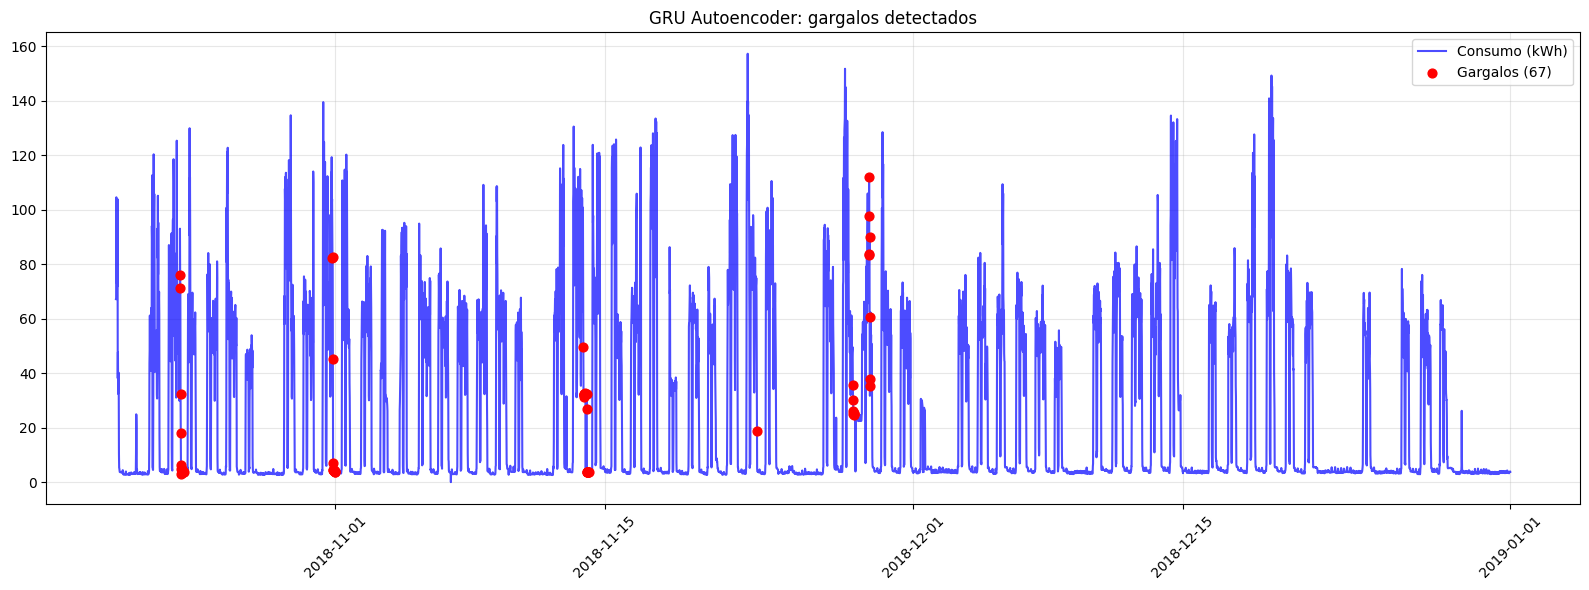

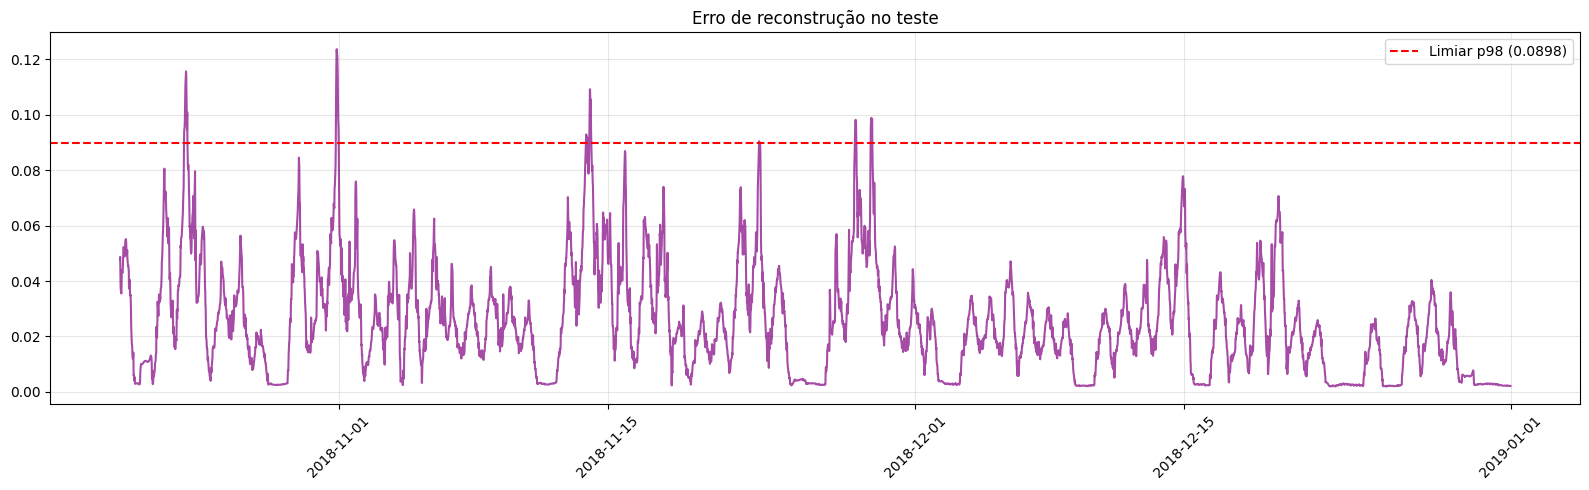

In [6]:
print("LIMIAR E DETECÇÃO (GRU AUTOENCODER)\n")

train_pred = gru.predict(X_train_g, verbose=0)
train_mae_loss = np.mean(np.abs(train_pred - X_train_g), axis=(1, 2))
threshold = np.percentile(train_mae_loss, 98)
print(f"Limiar (percentil 98 do erro de treino): {threshold:.6f}")

test_pred = gru.predict(X_test_g, verbose=0)
test_mae_loss = np.mean(np.abs(test_pred - X_test_g), axis=(1, 2))

# Cada janela i cobre os passos i..i+SEQ_LENGTH-1; rotulamos pela data do último passo da janela
test_index = df.index[N_TRAIN_ROWS:][SEQ_LENGTH - 1:]
scores = pd.DataFrame(index=test_index)
scores['loss'] = test_mae_loss
scores['anomaly'] = scores['loss'] > threshold
scores['Usage_kWh'] = df['Usage_kWh'].values[N_TRAIN_ROWS:][SEQ_LENGTH - 1:]

anomalies = scores[scores['anomaly']]
print(f"Janelas testadas: {len(scores)} | gargalos detectados: {len(anomalies)} ({100 * len(anomalies) / len(scores):.2f}%)")
if len(anomalies) > 0:
    print(f"Consumo médio nos gargalos: {anomalies['Usage_kWh'].mean():.2f} kWh")

# Rótulo de referência (proxy): consumo acima do percentil 90 do teste.
# Atenção: não é um rótulo de gargalo real, apenas uma referência para as métricas de classificação.
y_true = (scores['Usage_kWh'] > scores['Usage_kWh'].quantile(0.90)).astype(int)
y_pred = scores['anomaly'].astype(int)

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
print(f"\nPrecisão: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
print(f"VP={tp}  VN={tn}  FP={fp}  FN={fn}")

# Erro de reconstrução na escala original (kWh)
rng_g, mn_g = scaler_gru.data_range_[0], scaler_gru.data_min_[0]
diff_kwh = (test_pred - X_test_g) * rng_g
mae_kwh = np.mean(np.abs(diff_kwh))
rmse_kwh = np.sqrt(np.mean(diff_kwh ** 2))
print(f"\nReconstrução (kWh): MAE = {mae_kwh:.2f} | RMSE = {rmse_kwh:.2f}")

print("\nTop 10 gargalos por erro de reconstrução")
print(anomalies.nlargest(10, 'loss')[['Usage_kWh', 'loss']].to_string())

plt.figure(figsize=(16, 6))
plt.plot(scores.index, scores['Usage_kWh'], color='blue', alpha=0.7, label='Consumo (kWh)')
plt.scatter(anomalies.index, anomalies['Usage_kWh'], color='red', s=40, zorder=5,
            label=f'Gargalos ({len(anomalies)})')
plt.title('GRU Autoencoder: gargalos detectados'); plt.legend(); plt.grid(alpha=0.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

plt.figure(figsize=(16, 5))
plt.plot(scores.index, scores['loss'], color='purple', alpha=0.7)
plt.axhline(threshold, color='red', linestyle='--', label=f'Limiar p98 ({threshold:.4f})')
plt.title('Erro de reconstrução no teste'); plt.legend(); plt.grid(alpha=0.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Resumo e exportação dos modelos

In [7]:
print(f"TensorFlow {tf.__version__} | Keras {tf.keras.__version__}")
print("\nLSTM")
print(f"  MAE {mae_actual:.2f} kWh | RMSE {rmse_actual:.2f} kWh | R² {r2_actual:.4f}")
print(f"  Limiar {threshold_gargalo:.2f} kWh | gargalos {len(indices_gargalos)} ({percentual_gargalos:.2f}%)")
print("GRU Autoencoder")
print(f"  MAE {mae_kwh:.2f} kWh | RMSE {rmse_kwh:.2f} kWh | limiar p98 {threshold:.6f}")
print(f"  gargalos {len(anomalies)} ({100 * len(anomalies) / len(scores):.2f}%) | "
      f"precisão {precision:.4f} | recall {recall:.4f} | F1 {f1:.4f}")

# Empacota os modelos para baixar de uma vez (Hugging Face)
ARTIFACTS = ['lstm_model.keras', 'scaler.pkl', 'gru_autoencoder_model.keras', 'scaler_gru.pkl']
with zipfile.ZipFile('modelos_gargalos.zip', 'w') as z:
    for f in ARTIFACTS:
        z.write(f)
print("\nArquivo criado: modelos_gargalos.zip")
try:
    from google.colab import files
    files.download('modelos_gargalos.zip')
except ImportError:
    pass

TensorFlow 2.21.0 | Keras 3.13.2

LSTM
  MAE 5.00 kWh | RMSE 9.05 kWh | R² 0.9169
  Limiar 16.31 kWh | gargalos 534 (7.62%)
GRU Autoencoder
  MAE 3.78 kWh | RMSE 7.70 kWh | limiar p98 0.089782
  gargalos 67 (0.96%) | precisão 0.1343 | recall 0.0130 | F1 0.0237

Arquivo criado: modelos_gargalos.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>